# Iris Flower Classification
**CodeAlpha Data Science Internship — Task 1**

**Goal:** Train a machine learning model that predicts the species of an Iris flower
(*setosa*, *versicolor* or *virginica*) from four measurements: sepal length, sepal width,
petal length and petal width.

**Steps:**
1. Load and inspect the data
2. Exploratory data analysis (EDA)
3. Split into train and test sets
4. Train and compare several classifiers
5. Evaluate the best model (accuracy, confusion matrix, classification report)
6. Predict the species of a new flower

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load the data

In [2]:
df = pd.read_csv("data/Iris.csv")
print("Shape:", df.shape)
df.head()

Shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [4]:
print("Missing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.drop(columns="Id").duplicated().sum())
print("\nSamples per species:\n", df["Species"].value_counts())

Missing values per column:
 Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Duplicate rows: 3

Samples per species:
 Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


The dataset is clean: 150 rows, no missing values, and the three classes are perfectly
balanced (50 each). The `Id` column is just a row number, so we drop it.
The few duplicate rows are real flowers whose measurements happen to match other flowers,
so we keep them.

In [5]:
df = df.drop(columns="Id")
df["Species"] = df["Species"].str.replace("Iris-", "", regex=False)
features = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
df.describe().round(2)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.00,150.00,150.00,150.00
mean,5.84,3.05,3.76,1.20
std,0.83,0.43,1.76,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## 2. Exploratory data analysis

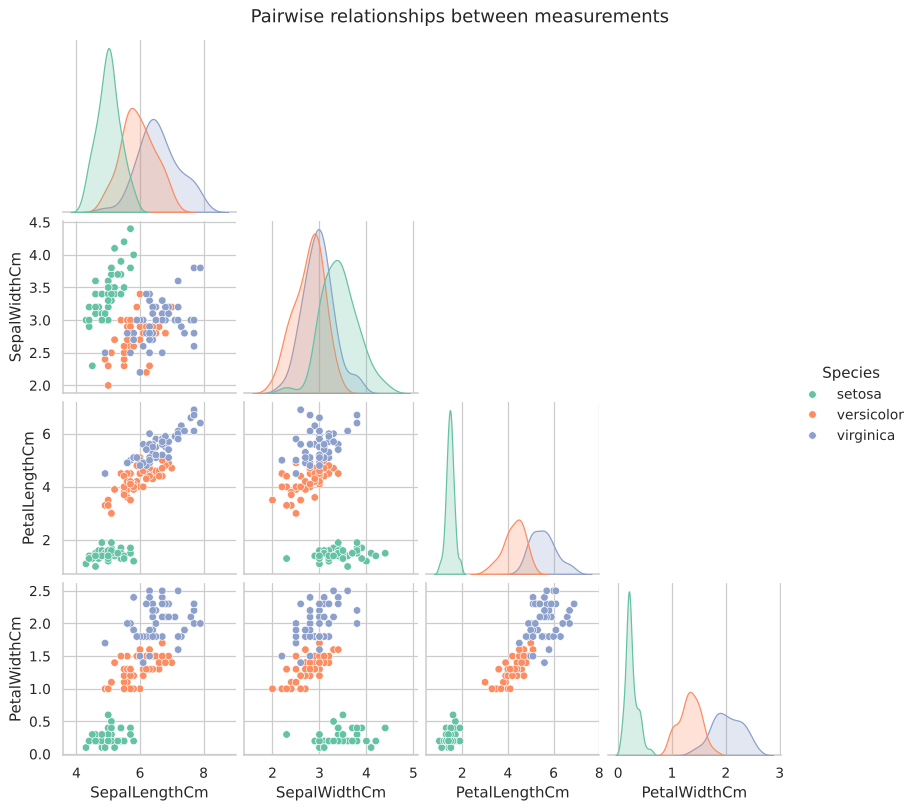

In [6]:
g = sns.pairplot(df, hue="Species", corner=True, palette="Set2", height=2.2)
g.figure.suptitle("Pairwise relationships between measurements", y=1.02)
g.savefig("images/pairplot.png", dpi=120, bbox_inches="tight")

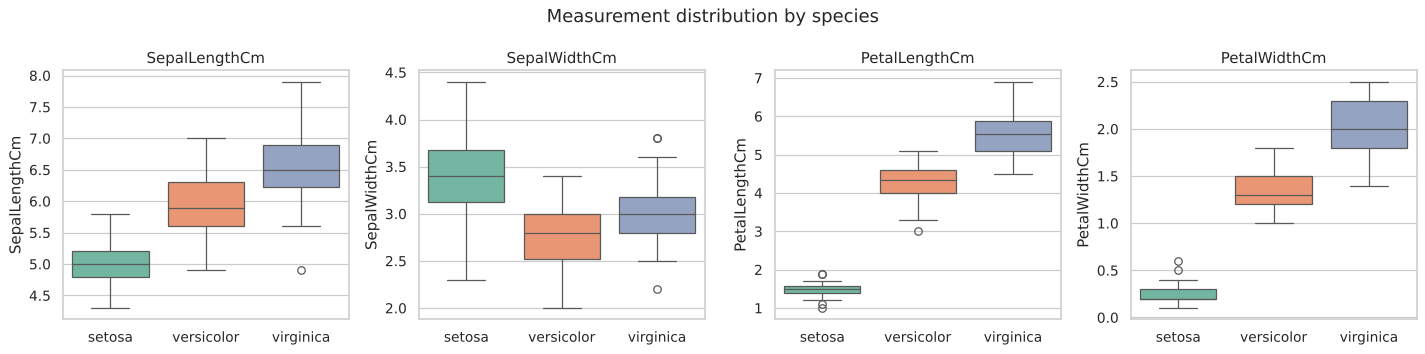

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, features):
    sns.boxplot(data=df, x="Species", y=col, hue="Species", palette="Set2", ax=ax, legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Measurement distribution by species")
plt.tight_layout()
fig.savefig("images/boxplots.png", dpi=120, bbox_inches="tight")

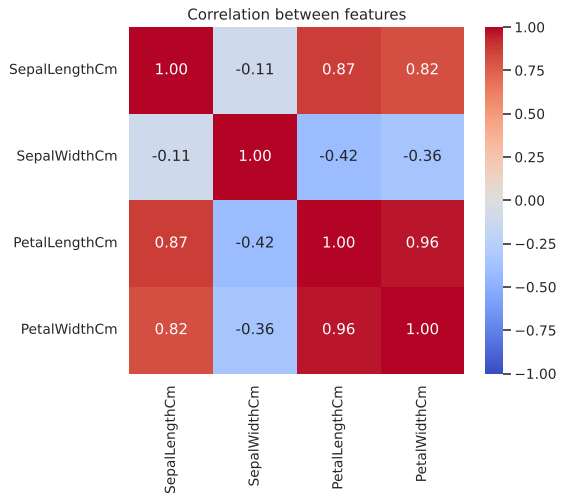

In [8]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation between features")
plt.savefig("images/correlation.png", dpi=120, bbox_inches="tight")

**Observations**
- **Petal length and petal width** separate the species best. *Setosa* is completely
  separated from the other two by petal size.
- *Versicolor* and *virginica* overlap a little, so most classification errors will happen
  between these two.
- Petal length and petal width are strongly correlated (≈ 0.96).
- Sepal width carries the least information on its own.

## 3. Train / test split
We keep 20% of the data aside as a test set. `stratify` keeps the same species
balance in both sets.

In [9]:
X = df[features]
encoder = LabelEncoder()
y = encoder.fit_transform(df["Species"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])

Train size: 120 | Test size: 30


## 4. Train and compare models
We compare five common classifiers with 5-fold cross-validation on the training set.
Models that depend on distances (Logistic Regression, KNN, SVM) are wrapped in a
pipeline with `StandardScaler`.

In [10]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "K-Nearest Neighbors": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Support Vector Machine": make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []
for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    model.fit(X_train, y_train)
    test_acc = accuracy_score(y_test, model.predict(X_test))
    results.append({"Model": name, "CV accuracy (mean)": cv_scores.mean(),
                    "CV std": cv_scores.std(), "Test accuracy": test_acc})

results_df = pd.DataFrame(results).sort_values("CV accuracy (mean)", ascending=False).reset_index(drop=True)
results_df.round(3)

,Model,CV accuracy (mean),CV std,Test accuracy
0,Support Vector Machine,0.967,0.017,0.967
1,Logistic Regression,0.958,0.026,0.933
2,K-Nearest Neighbors,0.958,0.026,0.933
3,Decision Tree,0.950,0.017,0.933
4,Random Forest,0.950,0.031,0.900


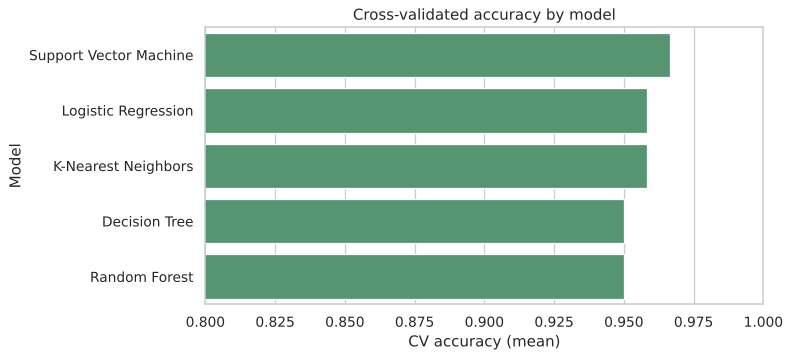

In [11]:
plt.figure(figsize=(8, 4))
sns.barplot(data=results_df, x="CV accuracy (mean)", y="Model", color="#4C9F70")
plt.xlim(0.8, 1.0)
plt.title("Cross-validated accuracy by model")
plt.savefig("images/model_comparison.png", dpi=120, bbox_inches="tight")

## 5. Evaluate the best model

In [12]:
best_name = results_df.loc[0, "Model"]
best_model = models[best_name]
y_pred = best_model.predict(X_test)

print(f"Best model: {best_name}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}\n")
print(classification_report(y_test, y_pred, target_names=encoder.classes_))

Best model: Support Vector Machine
Test accuracy: 96.67%

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



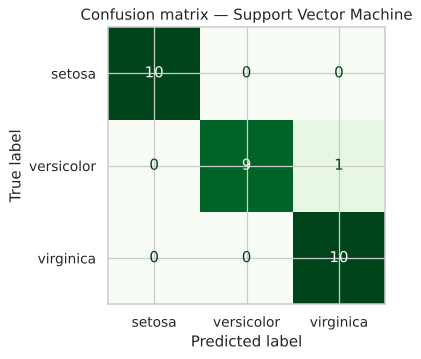

In [13]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=encoder.classes_).plot(
    cmap="Greens", ax=ax, colorbar=False)
ax.set_title(f"Confusion matrix — {best_name}")
fig.savefig("images/confusion_matrix.png", dpi=120, bbox_inches="tight")

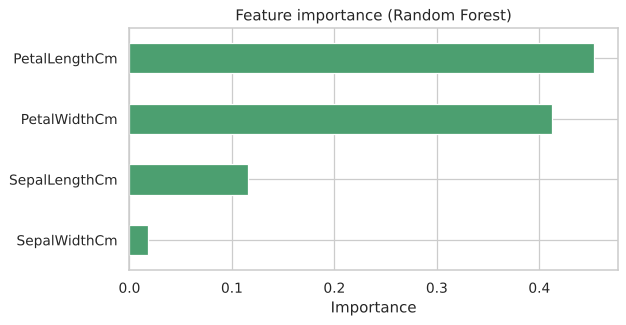

In [14]:
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=features).sort_values()
importance.plot(kind="barh", color="#4C9F70", figsize=(7, 3.5))
plt.title("Feature importance (Random Forest)")
plt.xlabel("Importance")
plt.savefig("images/feature_importance.png", dpi=120, bbox_inches="tight")

## 6. Predict a new flower

In [15]:
new_flowers = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2],   # looks like setosa
     [6.0, 2.9, 4.5, 1.5],   # looks like versicolor
     [6.9, 3.1, 5.8, 2.2]],  # looks like virginica
    columns=features,
)
predictions = encoder.inverse_transform(best_model.predict(new_flowers))
new_flowers.assign(PredictedSpecies=predictions)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,PredictedSpecies
0,5.1,3.5,1.4,0.2,setosa
1,6.0,2.9,4.5,1.5,versicolor
2,6.9,3.1,5.8,2.2,virginica


## Conclusion
- All models classify Iris flowers with high accuracy (above 90%), because the
  species are well separated by their measurements.
- **Petal length and petal width** are the most important features. Sepal width matters least.
- *Setosa* is always classified correctly. The few mistakes are between
  *versicolor* and *virginica*, which overlap slightly.
- The trained model can predict the species of any new flower from its four measurements.